# GPT 架构消融实验｜一份 Colab Notebook 完成全部实验

**从上到下运行即可**：准备一次中文 TinyStories 数据 → 原始 GPT Baseline → RMSNorm+RoPE → SwiGLU → 自动画 Loss 曲线。所有版本共用数据、参数规模预算、随机种子、训练步骤与验证窗口。

**最重要的设计**：对照实验不预设新组件一定更好；以相同 Token 预算下的 Validation Loss 为判断依据。Baseline = LayerNorm + Learned Absolute Embedding + ReLU FFN；另外两组只替换指定组件。最后可开启单组件消融。

*来源：整合原始 `gpt_dev_test.ipynb` 的 GPT 结构/中文注释及上一版八份实验 Notebook。自注意力统一使用 QKV 合并 + SDPA，消除不同版本实现速度的混杂。*

**运行方法**：在 Colab 选择 GPU（L4 / A100）；运行全部单元格。模型参数和日志分别保存到 Google Drive 的 `MyDrive/GPT_Ablation_Unified`，已完成的实验自动跳过，未完成的实验从最近 Checkpoint 继续。

**资源提示**：默认 3 组 × 4,000 步；如果需要更严谨的统计比较，之后可增加不同随机种子并将两种组件分别单独消融。

In [12]:
# Cell 1｜安装依赖、挂载 Drive、统一超参数（只改这里）
%pip -q install datasets tiktoken matplotlib pandas
import os, json, math, csv, time, random, hashlib, gc
from pathlib import Path
import torch
import torch.nn as nn
from torch.nn import functional as F
import tiktoken
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/GPT_Ablation_Unified')
except ImportError:
    ROOT = Path('./GPT_Ablation_Unified')
ROOT.mkdir(parents=True, exist_ok=True)
DATA_PATH = ROOT / 'tinystories_dataset.pt'

DATASET = 'RobinChen2001/TinyStories-Zh-2M'
N_STORIES = 50_000
SEED = 1337
batch_size = 16       #一個批次并行訓練多少組tokens，L4不足可降為8（所有組須相同）
block_size = 256      #一組裏面有多少tokens
max_iters = 4000      #每個模型相同訓練步數；可改6000，但所有組應保持一致
eval_interval = 200   #多久做一次eval
eval_iters = 12       #固定驗證批次數，三組共用
learning_rate = 3e-4  #LR嘛 學習率
warmup_iters = 200
min_lr = 3e-5
n_embd = 384          #表徵空間大小
n_head = 6            #multi-head attention
n_layer = 8           #訓練幾層block
dropout = 0.1
weight_decay = 0.1
checkpoint_interval = 200

# 8组完整消融实验：(名称, 是否启用RMSNorm, 是否启用RoPE, 是否启用SwiGLU)
EXPERIMENTS = [
    ('baseline', False, False, False),       # 000
    ('rms_only', True, False, False),        # 100
    ('rope_only', False, True, False),       # 010
    ('swiglu_only', False, False, True),     # 001
    ('rms_rope', True, True, False),         # 110
    ('rms_swiglu', True, False, True),       # 101
    ('rope_swiglu', False, True, True),      # 011
    ('all_three', True, True, True),         # 111
]

device = 'cuda' if torch.cuda.is_available() else 'cpu' #能用cuda用cuda
if device == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.set_float32_matmul_precision('high')
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU mode: functional checks only; full training requires GPU.')
print('Output directory:', ROOT)
print('Experiment order:', [e[0] for e in EXPERIMENTS])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4
Output directory: /content/drive/MyDrive/GPT_Ablation_Unified
Experiment order: ['baseline', 'rms_only', 'rope_only', 'swiglu_only', 'rms_rope', 'rms_swiglu', 'rope_swiglu', 'all_three']


## 1｜只准备一次数据集

从 Hugging Face 串流采样 50,000 篇中文 TinyStories。**先按故事分 Train/Val，再分词**；压缩词表仅用 Train 建立，验证集未出现的 Token 映射到 `<UNK>`（ID=0）。数据指纹写入检查点，避免不同实验错用语料。下次重跑会直接加载 Drive 中保存的数据，无需重新下载。

In [13]:
# Cell 2｜数据下载、分词、固定划分；若 Drive 已有数据则直接复用
if DATA_PATH.exists():
    payload = torch.load(DATA_PATH, map_location='cpu', weights_only=False)
    assert payload['dataset'] == DATASET and payload['requested_stories'] == N_STORIES and payload['seed'] == SEED, '当前数据缓存和配置不同，请更换 ROOT 或手动备份重建数据。'
    print('Loaded shared dataset from Drive:', DATA_PATH)
else:
    ds = load_dataset(DATASET, split='train', streaming=True)
    stories = []
    for row in ds.take(N_STORIES):
        s = row['text'].strip()
        if len(s) >= 20: stories.append(s)
    assert len(stories) > 1000
    rng = random.Random(SEED)
    rng.shuffle(stories)
    cut = int(len(stories)*0.9)
    train_stories, val_stories = stories[:cut], stories[cut:]
    print('Downloaded stories:', len(stories), 'Preview:', repr(stories[0][:120]))

    enc = tiktoken.get_encoding('cl100k_base')
    train_raw = torch.tensor(enc.encode('\n\n'.join(train_stories)), dtype=torch.long)
    val_raw = torch.tensor(enc.encode('\n\n'.join(val_stories)), dtype=torch.long)
    unique_ids = torch.unique(train_raw, sorted=True)
    vocab = len(unique_ids)+1  # ID 0 是 <UNK>
    train_ids = torch.searchsorted(unique_ids, train_raw)+1
    positions = torch.searchsorted(unique_ids, val_raw)
    inside = positions < len(unique_ids)
    valid = torch.zeros_like(inside)
    valid[inside] = unique_ids[positions[inside]] == val_raw[inside]
    val_ids = torch.zeros_like(positions)
    val_ids[valid] = positions[valid]+1
    digest = hashlib.sha256()
    for t in (train_ids, val_ids, unique_ids):
        digest.update(t.numpy().tobytes())
    payload = dict(train_ids=train_ids, val_ids=val_ids,
                   unique_ids=unique_ids, vocab_size=vocab,
                   dataset_sha256=digest.hexdigest(), dataset=DATASET,
                   requested_stories=N_STORIES, stories_found=len(stories), seed=SEED,
                   val_oov_rate=(~valid).float().mean().item())
    torch.save(payload, DATA_PATH)
    print('Saved dataset to Drive:', DATA_PATH)

train_data, val_data = payload['train_ids'], payload['val_ids']
unique_ids, vocab_size = payload['unique_ids'], payload['vocab_size']
assert len(train_data)>block_size+1 and len(val_data)>block_size+1
print('Training tokens:',f'{len(train_data):,}','Validation tokens:',f'{len(val_data):,}')
print('Compact vocabulary:',vocab_size,'Val OOV:',payload['val_oov_rate'])
print('Dataset fingerprint:',payload['dataset_sha256'][:20])
# 不改变数据之后再次执行本格：不会影响已训练权重。

Loaded shared dataset from Drive: /content/drive/MyDrive/GPT_Ablation_Unified/tinystories_dataset.pt
Training tokens: 15,130,642 Validation tokens: 1,680,228
Compact vocabulary: 1734 Val OOV: 4.761258605867624e-05
Dataset fingerprint: 7598be6b135b151f87e3


## 2｜统一的 GPT 结构（保留原始代码注释）

以下模型原理与原始 Notebook 相同：Embedding → MultiHeadAttention → FFN → 残差 → LM Head。所有实验共享 QKV 合并、SDPA 等**工程实现**；开关仅决定 Normalization、Position Encoding、FFN。新旧 FFN 中间宽度选择使权重参数量基本相等；Bias 和位置向量会导致小幅参数差异。

In [14]:
# Cell 3｜模型定义（仅执行一次即可）
USE_RMS = False
USE_ROPE = False
USE_SWIGLU = False
# Head → MultiHeadAttention：把原先 6 个 Head 的 Q/K/V 合并为一次矩阵投影。
# 这样 GPU 少做许多小算子；对所有实验采用同样实现，保持公平。
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        # RMS(x) = sqrt(mean(x^2) + eps)，没有减去均值
        xf = x.float()
        normed = xf * torch.rsqrt(xf.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return normed.to(x.dtype) * self.weight


def make_norm(dim):
    return RMSNorm(dim) if USE_RMS else nn.LayerNorm(dim)


class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """
    def __init__(self, num_heads, head_size): #自定義需要head數量+head長度
        super().__init__()
        assert num_heads * head_size == n_embd
        assert head_size % 2 == 0
        self.num_heads, self.head_size = num_heads, head_size
        self.qkv = nn.Linear(n_embd, 3*n_embd, bias=False)
        #每个head都学习一套表征的不同侧面，Q K V 仍然分别存在
        self.proj = nn.Linear(n_embd, n_embd) #反正再映射一層
        self.dropout = nn.Dropout(dropout)
        if USE_ROPE:
            freq = 10000 ** (-2 * torch.arange(head_size//2, dtype=torch.float32) / head_size)
            self.register_buffer('inv_freq', freq, persistent=False)

    def apply_rope(self, q, k):
        # q/k: [B, heads, T, head_size]，把相邻坐标两两配对旋转
        T = q.size(-2)
        pos = torch.arange(T, device=q.device, dtype=torch.float32)
        angles = pos[:, None] * self.inv_freq[None, :]
        cos = angles.cos().to(dtype=q.dtype)[None,None,:,:]
        sin = angles.sin().to(dtype=q.dtype)[None,None,:,:]
        def rotate(v):
            pairs = v.reshape(*v.shape[:-1], self.head_size//2, 2)
            x, y = pairs[...,0], pairs[...,1]
            return torch.stack((x*cos-y*sin, x*sin+y*cos), dim=-1).flatten(-2)
        return rotate(q), rotate(k)

    def forward(self, x):
        B,T,C = x.shape
        q,k,v = self.qkv(x).chunk(3,dim=-1)
        q = q.view(B,T,self.num_heads,self.head_size).transpose(1,2)
        k = k.view(B,T,self.num_heads,self.head_size).transpose(1,2)
        v = v.view(B,T,self.num_heads,self.head_size).transpose(1,2)
        if USE_ROPE:
            q,k = self.apply_rope(q,k) #RoPE 只旋转 Q/K，不改变 V
        # SDPA 内部完成 QK^T / sqrt(head_size)、下三角mask、softmax、attention@v
        out = F.scaled_dot_product_attention(
            q,k,v, is_causal=True, dropout_p=dropout if self.training else 0.0)
        out = out.transpose(1,2).contiguous().view(B,T,C)
        return self.dropout(self.proj(out))


class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """
    def __init__(self, n_embd):
        super().__init__()
        if USE_SWIGLU:
            hidden_dim = 8*n_embd//3 #三条矩阵使权重参数量约等于原来 4d 的两层 FFN
            self.gate_proj = nn.Linear(n_embd, hidden_dim, bias=False)
            self.up_proj = nn.Linear(n_embd, hidden_dim, bias=False)
            self.down_proj = nn.Linear(hidden_dim, n_embd, bias=False)
            self.dropout = nn.Dropout(dropout)
        else:
            self.net = nn.Sequential(
                nn.Linear(n_embd, 4 * n_embd),#放大四倍
                nn.ReLU(),#非綫性層
                nn.Linear(4 * n_embd, n_embd),#恢復原先參數量級
                nn.Dropout(dropout),#drop一手
            ) #反正sequential就是組裝一些基本block

    def forward(self, x):
        if USE_SWIGLU:
            return self.dropout(self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x)))
        return self.net(x) #again Module的定義裏面直接調用feedforward


class Block(nn.Module):
    """ Transformer block: communication followed by computation """
    def __init__(self, n_embd, n_head): #需要C和N
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size) #寫過了
        self.ffwd = FeedFoward(n_embd) #寫過了
        self.ln1 = make_norm(n_embd)
        self.ln2 = make_norm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))  #normalize+resnet處理梯度
        x = x + self.ffwd(self.ln2(x)) #normalize+resnet處理梯度
        return x


class BigramLanguageModel(nn.Module): #好的我們重寫這個大類（实际是 decoder-only GPT）
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd) #每個詞的表徵空間
        if not USE_ROPE:
            self.position_embedding_table = nn.Embedding(block_size, n_embd)#每個詞的位置編碼
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        #跑n_layer輪的Block 然後用*解開list放到sequential裏
        self.ln_f = make_norm(n_embd) #做一層norm
        self.lm_head = nn.Linear(n_embd, vocab_size) #把每個token的維度表示映射成vocab size上的打分

    def forward(self, idx, targets=None):
        B,T = idx.shape
        assert T <= block_size
        tok_emb = self.token_embedding_table(idx) #查表
        if USE_ROPE:
            x = tok_emb #RoPE 不直接加 learned position embedding
        else:
            pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))
            x = tok_emb + pos_emb #加起來啦 broadcast
        x = self.blocks(x) #跑一遍blocks
        x = self.ln_f(x) #跑一遍norm
        logits = self.lm_head(x) #映射成词表上的打分
        loss = None
        if targets is not None:
            B,T,V = logits.shape
            loss = F.cross_entropy(logits.reshape(B*T,V), targets.reshape(B*T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=160, temperature=0.8, top_k=40):
        was_training = self.training
        self.eval()
        try:
            for _ in range(max_new_tokens):
                idx_cond = idx[:, -block_size:] #取最後blocksize個token啦
                with torch.autocast('cuda',dtype=torch.bfloat16,enabled=device=='cuda'):
                    logits,_ = self(idx_cond)
                logits = logits[:,-1,:].float() / temperature #只拿最後一組logits
                v,_ = torch.topk(logits, min(top_k, logits.shape[-1]))
                logits = logits.masked_fill(logits < v[:,-1,None], float('-inf'))
                probs = F.softmax(logits,dim=-1)
                idx_next = torch.multinomial(probs,num_samples=1)
                idx = torch.cat((idx,idx_next),dim=1) #拼接進去新的内容
        finally:
            self.train(was_training)
        return idx



## 3｜训练和断点恢复逻辑

每一个版本在自己的子文件夹保存 `loss.csv`、`last.pt`、`best.pt`、`config.json`。固定评估窗口和训练窗口随机数种子；使用 BF16、梯度裁剪、Warmup + Cosine LR。**不要在训练中更换超参数**，否则对照不再公平。中断或断线后重新运行同一份 Notebook，会恢复对应版本的进度。

In [18]:
# Cell 4｜公共训练函数，所有模型用完全相同的训练方法

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def fixed_batches(source, sample_seed):
    rng = torch.Generator().manual_seed(sample_seed)
    indices = torch.randint(len(source)-block_size-1,(eval_iters*batch_size,),generator=rng)
    xs = torch.stack([source[i:i+block_size] for i in indices]).split(batch_size)
    ys = torch.stack([source[i+1:i+block_size+1] for i in indices]).split(batch_size)
    return list(zip(xs,ys))

# 固定 eval windows，所有版本一模一样
fixed_eval = {'train':fixed_batches(train_data,4101),
              'val':fixed_batches(val_data,4102)}

def learning_rate_at(step):
    if step < warmup_iters:
        return learning_rate*(step+1)/warmup_iters
    ratio = min(1.0, (step-warmup_iters)/max(1, max_iters-warmup_iters))
    return min_lr + 0.5*(learning_rate-min_lr)*(1+math.cos(math.pi*ratio))

@torch.no_grad()
def eval_model(model):
    model.eval()
    results = {}
    for split in ('train','val'):
        losses = []
        for X,Y in fixed_eval[split]:
            with torch.autocast('cuda',dtype=torch.bfloat16,enabled=(device=='cuda')):
                _, loss = model(X.to(device),Y.to(device))
            losses.append(loss.item())
        results[split] = sum(losses)/len(losses)
    model.train()
    return results

def train_one_variant(tag, use_rms, use_rope, use_swiglu):
    global USE_RMS, USE_ROPE, USE_SWIGLU
    USE_RMS, USE_ROPE, USE_SWIGLU = use_rms, use_rope, use_swiglu
    set_seed(SEED)
    run_dir = ROOT/tag
    run_dir.mkdir(parents=True,exist_ok=True)
    log_path = run_dir/'loss.csv'
    last_path = run_dir/'last.pt'
    best_path = run_dir/'best.pt'
    config_path = run_dir/'config.json'
    train_rng = torch.Generator().manual_seed(9001)

    model = BigramLanguageModel().to(device)
    optimizer = torch.optim.AdamW(model.parameters(),lr=learning_rate,weight_decay=weight_decay)
    param_count = sum(p.numel() for p in model.parameters())
    config = dict(variant=tag,rms=use_rms,rope=use_rope,swiglu=use_swiglu,
                  dataset_hash=payload['dataset_sha256'],vocab_size=vocab_size,
                  batch_size=batch_size,block_size=block_size,max_iters=max_iters,
                  eval_interval=eval_interval,eval_iters=eval_iters,
                  learning_rate=learning_rate,warmup_iters=warmup_iters,min_lr=min_lr,
                  n_embd=n_embd,n_head=n_head,n_layer=n_layer,dropout=dropout,
                  weight_decay=weight_decay,seed=SEED,parameters=param_count)
    if config_path.exists():
        old_config = json.loads(config_path.read_text())
        assert old_config==config, f'{tag}: 保存的实验配置不匹配；请不要混用实验结果。'
    else:
        config_path.write_text(json.dumps(config,ensure_ascii=False,indent=2))
    global_step=0
    best_val=float('inf')
    history=[]

    def save_ckpt(path):
        state = dict(model={k:v.detach().cpu() for k,v in model.state_dict().items()},
                     optimizer=optimizer.state_dict(),global_step=global_step,
                     best_val=best_val,history=history,config=config,
                     train_rng_state=train_rng.get_state().cpu(),
                     torch_rng_state=torch.get_rng_state().cpu(),
                     cuda_rng_state=torch.cuda.get_rng_state_all() if device=='cuda' else None)
        tmp=path.with_suffix('.tmp')
        torch.save(state,tmp)
        os.replace(tmp,path)

    if last_path.exists():
        ckpt=torch.load(last_path,map_location=device,weights_only=False)
        assert ckpt['config']==config, 'Checkpoint 的配置不一致。'
        model.load_state_dict(ckpt['model'])
        optimizer.load_state_dict(ckpt['optimizer'])
        global_step=ckpt['global_step']; best_val=ckpt['best_val']; history=ckpt['history']

        try:
            rng_state = ckpt['train_rng_state']
            if isinstance(rng_state, torch.Tensor):
                rng_state = rng_state.cpu().to(torch.uint8)
            train_rng.set_state(rng_state)
        except Exception as e:
            print(f"Warning: Failed to load train_rng_state ({e})")

        try:
            torch_rng = ckpt['torch_rng_state']
            if isinstance(torch_rng, torch.Tensor):
                torch_rng = torch_rng.cpu().to(torch.uint8)
            torch.set_rng_state(torch_rng)
        except Exception as e:
            print(f"Warning: Failed to load torch_rng_state ({e})")

        if device=='cuda' and ckpt['cuda_rng_state'] is not None:
            try:
                torch.cuda.set_rng_state_all([s.cpu().to(torch.uint8) if isinstance(s, torch.Tensor) else s for s in ckpt['cuda_rng_state']])
            except Exception as e:
                print(f"Warning: Failed to load cuda_rng_state ({e})")

        print(f'[{tag}] Resumed at step {global_step}/{max_iters}')
    else:
        if log_path.exists():
            raise RuntimeError(f'{tag} 有旧 loss.csv 但缺少 last.pt，请先备份并检查。')
        with open(log_path,'w',newline='') as f:
            csv.writer(f).writerow(['variant','step','epoch','train_loss','val_loss','lr','elapsed_seconds'])
        print(f'[{tag}] START FRESH, {param_count/1e6:.3f} M params')

    if global_step >= max_iters:
        print(f'[{tag}] already completed, skipping.')
        del model,optimizer
        gc.collect()
        if device=='cuda': torch.cuda.empty_cache()
        return

    model.train()
    start_time=time.perf_counter()
    try:
        while global_step < max_iters:
            step=global_step
            lr=learning_rate_at(step)
            for group in optimizer.param_groups: group['lr']=lr
            if step % eval_interval==0 or step==max_iters-1:
                losses=eval_model(model)
                epoch=step*batch_size*block_size/len(train_data)
                row=dict(variant=tag,step=step,epoch=epoch,
                         train_loss=losses['train'],val_loss=losses['val'],
                         lr=lr,elapsed_seconds=time.perf_counter()-start_time)
                history.append(row)
                with open(log_path,'a',newline='') as f:
                    csv.writer(f).writerow([row[k] for k in ('variant','step','epoch','train_loss','val_loss','lr','elapsed_seconds')])
                print(f'[{tag}] step {step:5d} | epoch* {epoch:.3f} | train {losses["train"]:.4f} | val {losses["val"]:.4f}')
                if losses['val']<best_val:
                    best_val=losses['val']
                    save_ckpt(best_path)
                save_ckpt(last_path)

            indices=torch.randint(len(train_data)-block_size-1,(batch_size,),generator=train_rng)
            xb=torch.stack([train_data[i:i+block_size] for i in indices]).to(device)
            yb=torch.stack([train_data[i+1:i+block_size+1] for i in indices]).to(device)
            with torch.autocast('cuda',dtype=torch.bfloat16,enabled=(device=='cuda')):
                _,loss=model(xb,yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step()
            global_step+=1
            if global_step % checkpoint_interval == 0:
                save_ckpt(last_path)
        save_ckpt(last_path)
        print(f'[{tag}] COMPLETED | best val={best_val:.4f}')
    except KeyboardInterrupt:
        save_ckpt(last_path)
        print(f'[{tag}] interrupted; progress saved.')
        raise
    finally:
        del model, optimizer
        gc.collect()
        if device=='cuda': torch.cuda.empty_cache()

## 4｜一键顺序训练三组模型

这个 Cell 按顺序执行三个实验。**在 Colab 停止/中断后，直接重跑此 Cell**：已完成模型会跳过，正在训练的模型从 `last.pt` 继续。不要清空 Drive 的实验目录。需要进一步区分 RMSNorm 与 RoPE 的独立贡献时，在 Cell 1 中打开 `RUN_EXTRA_ABLATIONS`，重新执行 Cell 1、Cell 3、Cell 4、Cell 5。

In [19]:
# Cell 5｜一键运行；把这一格跑完，三组实验就连贯完成
for tag,rms,rope,swiglu in EXPERIMENTS:
    print('\n'+'='*70+'\nRunning:',tag,'\n'+'='*70)
    train_one_variant(tag,rms,rope,swiglu)
print('\nAll selected ablations finished. Continue to comparison plots.')


Running: baseline 
[baseline] Resumed at step 4000/4000
[baseline] already completed, skipping.

Running: rms_only 
[rms_only] START FRESH, 15.612 M params
[rms_only] step     0 | epoch* 0.000 | train 7.6314 | val 7.6309
[rms_only] step   200 | epoch* 0.054 | train 3.4144 | val 3.4331
[rms_only] step   400 | epoch* 0.108 | train 2.9989 | val 3.0222
[rms_only] step   600 | epoch* 0.162 | train 2.6623 | val 2.6712
[rms_only] step   800 | epoch* 0.217 | train 2.4030 | val 2.4075
[rms_only] step  1000 | epoch* 0.271 | train 2.2333 | val 2.2435
[rms_only] step  1200 | epoch* 0.325 | train 2.1196 | val 2.1219
[rms_only] step  1400 | epoch* 0.379 | train 2.0311 | val 2.0326
[rms_only] step  1600 | epoch* 0.433 | train 1.9547 | val 1.9521
[rms_only] step  1800 | epoch* 0.487 | train 1.8945 | val 1.8946
[rms_only] step  2000 | epoch* 0.541 | train 1.8474 | val 1.8503
[rms_only] step  2200 | epoch* 0.596 | train 1.8038 | val 1.8088
[rms_only] step  2400 | epoch* 0.650 | train 1.7674 | val 1.772

## 5｜一键自动可视化比较

横轴是 **等效 Epoch** = 随机窗口呈现的 Token 数 / 训练集 Token 数（不是严格顺序遍历一轮）；同时画 Train / Validation Loss。每组都是相同训练 Token 预算、相同固定评估批次。为了严谨，不能只凭单个随机种子就宣称组件在统计上显著胜出。

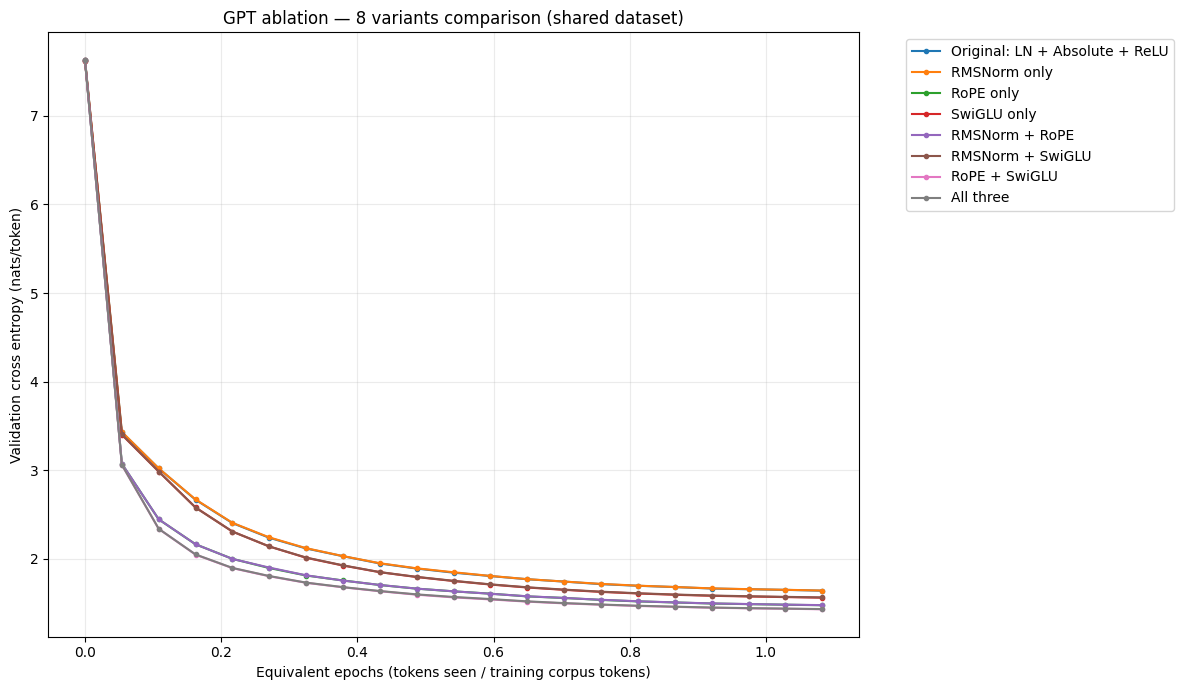


Best Validation Loss (descriptive only; verify reproducibility with multiple seeds):
label
RoPE + SwiGLU                     1.433116
All three                         1.434877
RoPE only                         1.478376
RMSNorm + RoPE                    1.479602
SwiGLU only                       1.563449
RMSNorm + SwiGLU                  1.566593
Original: LN + Absolute + ReLU    1.642570
RMSNorm only                      1.644219

Training records: 168


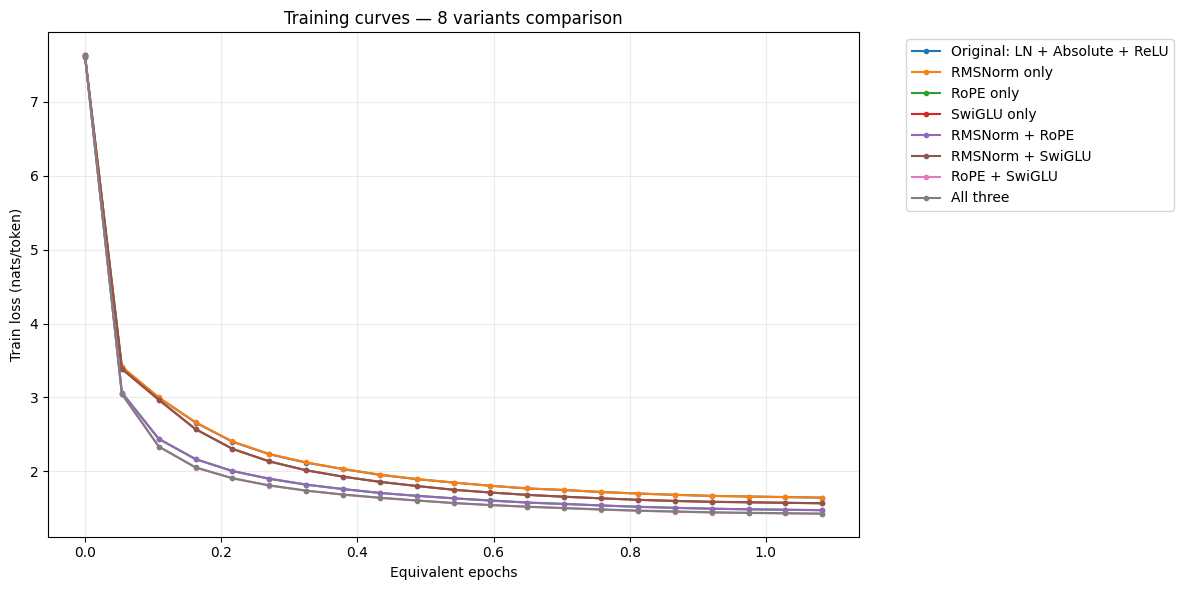

In [21]:
# Cell 6｜自动显示模型对照图与最优验证损失
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

name_map = {
    'baseline': 'Original: LN + Absolute + ReLU',
    'rms_only': 'RMSNorm only',
    'rope_only': 'RoPE only',
    'swiglu_only': 'SwiGLU only',
    'rms_rope': 'RMSNorm + RoPE',
    'rms_swiglu': 'RMSNorm + SwiGLU',
    'rope_swiglu': 'RoPE + SwiGLU',
    'all_three': 'All three'
}

frames = []
for tag, label in name_map.items():
    p = ROOT / tag / 'loss.csv'
    if p.exists():
        d = pd.read_csv(p)
        d['label'] = label
        frames.append(d)

if not frames:
    raise FileNotFoundError('还没有实验结果；请先运行 Cell 5')

df = pd.concat(frames, ignore_index=True)
plt.figure(figsize=(12, 7))
for label, g in df.groupby('label', sort=False):
    g = g.sort_values('epoch')
    plt.plot(g['epoch'], g['val_loss'], marker='.', label=label)
plt.xlabel('Equivalent epochs (tokens seen / training corpus tokens)')
plt.ylabel('Validation cross entropy (nats/token)')
plt.title('GPT ablation — 8 variants comparison (shared dataset)')
plt.grid(alpha=.25)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print('\nBest Validation Loss (descriptive only; verify reproducibility with multiple seeds):')
print(df.groupby('label')['val_loss'].min().sort_values().to_string())
print('\nTraining records:', len(df))

plt.figure(figsize=(12, 6))
for label, g in df.groupby('label', sort=False):
    g = g.sort_values('epoch')
    plt.plot(g['epoch'], g['train_loss'], marker='.', label=label)
plt.xlabel('Equivalent epochs')
plt.ylabel('Train loss (nats/token)')
plt.title('Training curves — 8 variants comparison')
plt.grid(alpha=.25)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6｜可选：加载最优模型生成样例

模型和 tokenizer 都在当前 Notebook 内；从 `best.pt` 加载权重，直接使用训练集实际出现的紧凑 Token ID 作提示，避免原始 `cl100k_base` 的大编号触发 CUDA 越界。生成前不需要重新运行训练。

In [22]:
# Cell 7｜可选，选择哪个模型生成故事
SAMPLE_VARIANT = 'rms_rope'  # baseline / rms_rope / swiglu
flags = {e[0]:e[1:] for e in EXPERIMENTS}
assert SAMPLE_VARIANT in flags
USE_RMS,USE_ROPE,USE_SWIGLU = flags[SAMPLE_VARIANT]
set_seed(SEED)
sample_model = BigramLanguageModel().to(device)
checkpoint=torch.load(ROOT/SAMPLE_VARIANT/'best.pt',map_location=device,weights_only=False)
sample_model.load_state_dict(checkpoint['model'])
sample_model.eval()
# 取训练集真实的 16 个 token，不跨越压缩词表
context = train_data[100:116].unsqueeze(0).to(device)
output = sample_model.generate(context, max_new_tokens=160)
# ID 0 是 <UNK>，无法用原始 tiktoken 直接解码；以替代标记显示
enc = tiktoken.get_encoding('cl100k_base')
def decode_compact(ids):
    parts=[]
    for idx in ids:
        if idx==0:
            parts.append('�')
        else:
            parts.append(enc.decode([int(unique_ids[idx-1])]))
    return ''.join(parts)
print(decode_compact(output[0].cpu().tolist()))
del sample_model
if device=='cuda': torch.cuda.empty_cache()

的主人��应了，然后他们去了海��。在海��上，他们看到了一��大��。����上有一��长��子。��问他们是否��意和他的��友们是否可以��子。��说他们应该��他们感��好一点，因为他们��找��找，但没有找到。
这个��事的��意是，即使有时，我们应该始��小心��不要再������个人了。��现在已经过了，而��有��多��友是��的。他们����自
